<div align="center">

![Course](https://img.shields.io/badge/Course-Advanced%20Data%20Science%20Lab-blue?style=for-the-badge&logo=python&logoColor=white)
![Code](https://img.shields.io/badge/Code-MCA33PE21-informational?style=for-the-badge)
![Assignment](https://img.shields.io/badge/Assignment-Formative%20Assessment%2002-success?style=for-the-badge)

---

# Advanced Data Science Lab [MCA33PE21]
## Formative Assessment - 02 (FA2) Activity
### Topic: Case Study - Data Analysis Using Machine Learning & Streamlit App Deployment [CO1 To CO4]

---
<br>

| Field | Details |
|---|---|
| **Academic Year** | **2026-2027** |
| **Class / Division** | **SYMCA (Semester-I)** |
| **PRN** | **125M1H060** |
| **Student Name** | **Nishant Nitin Wadkar** |
| **Submission Date** | **01/10/2026** |
</div>


---
## Instructions to Students

- Fill in your **PRN**, **Name**, **Class/Division**, and **Submission Date** in the header table above.
- Write all Python code in the code cells provided below each question.
- Execute each code cell and ensure there are **no errors** before submission.
- Submit the completed `.ipynb` file, `app.py` script, and summary PDF report on Google Classroom.

---


## Part 1: Data Acquisition & Preprocessing [05 Marks]
---
### 1.1 Dataset Selection & Overview
We select the **UCI Heart Disease Dataset**, a standard real-world medical diagnostic dataset used for binary classification. The goal is to predict whether a patient has heart disease (`1: Presence`) or not (`0: Absence`) based on 13 key clinical features including age, sex, chest pain type, blood pressure, cholesterol, ECG results, max heart rate, exercise angina, ST depression, slope, major vessels, and thalassemia.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Load dataset
df = pd.read_csv('heart_disease_fa2.csv')
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()
df.head()

Dataset Shape: (250, 14)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            250 non-null    int64  
 1   sex            250 non-null    int64  
 2   cp             250 non-null    int64  
 3   trestbps       250 non-null    int64  
 4   chol           250 non-null    int64  
 5   fbs            250 non-null    int64  
 6   restecg        250 non-null    int64  
 7   thalach        250 non-null    int64  
 8   exang          250 non-null    int64  
 9   oldpeak        250 non-null    float64
 10  slope          250 non-null    int64  
 11  ca             250 non-null    int64  
 12  thal           250 non-null    int64  
 13  heart_disease  250 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 27.5 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heart_disease
0,67,1,0,157,286,0,0,122,0,3.3,2,1,3,1
1,57,1,0,111,293,0,1,149,0,0.7,1,3,1,1
2,43,1,2,167,253,0,1,100,0,1.1,1,0,2,1
3,71,1,0,127,164,0,0,176,1,4.3,0,2,2,0
4,36,0,0,178,207,0,0,121,1,1.1,1,0,2,0


### 1.2 Summary Statistics & Data Quality Inspection


In [2]:
# Display summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,250.0,51.9280,13.898182,29.0,39.25,52.0,64.000,76.0
sex,250.0,0.6040,0.490045,0.0,0.00,1.0,1.000,1.0
cp,250.0,1.0280,1.058156,0.0,0.00,1.0,2.000,3.0
trestbps,250.0,136.9360,25.369635,95.0,115.25,139.0,159.000,179.0
chol,250.0,236.2520,62.472199,126.0,179.25,239.5,285.000,349.0
fbs,250.0,0.1280,0.334760,0.0,0.00,0.0,0.000,1.0
restecg,250.0,0.5560,0.551435,0.0,0.00,1.0,1.000,2.0
thalach,250.0,133.1640,37.571580,71.0,103.00,133.0,165.000,201.0
exang,250.0,0.2840,0.451841,0.0,0.00,0.0,1.000,1.0
oldpeak,250.0,2.2796,1.233479,0.0,1.20,2.4,3.375,4.5


### 1.3 Exploratory Data Analysis (EDA)
Visualize feature distributions and relationships with the target diagnosis variable.


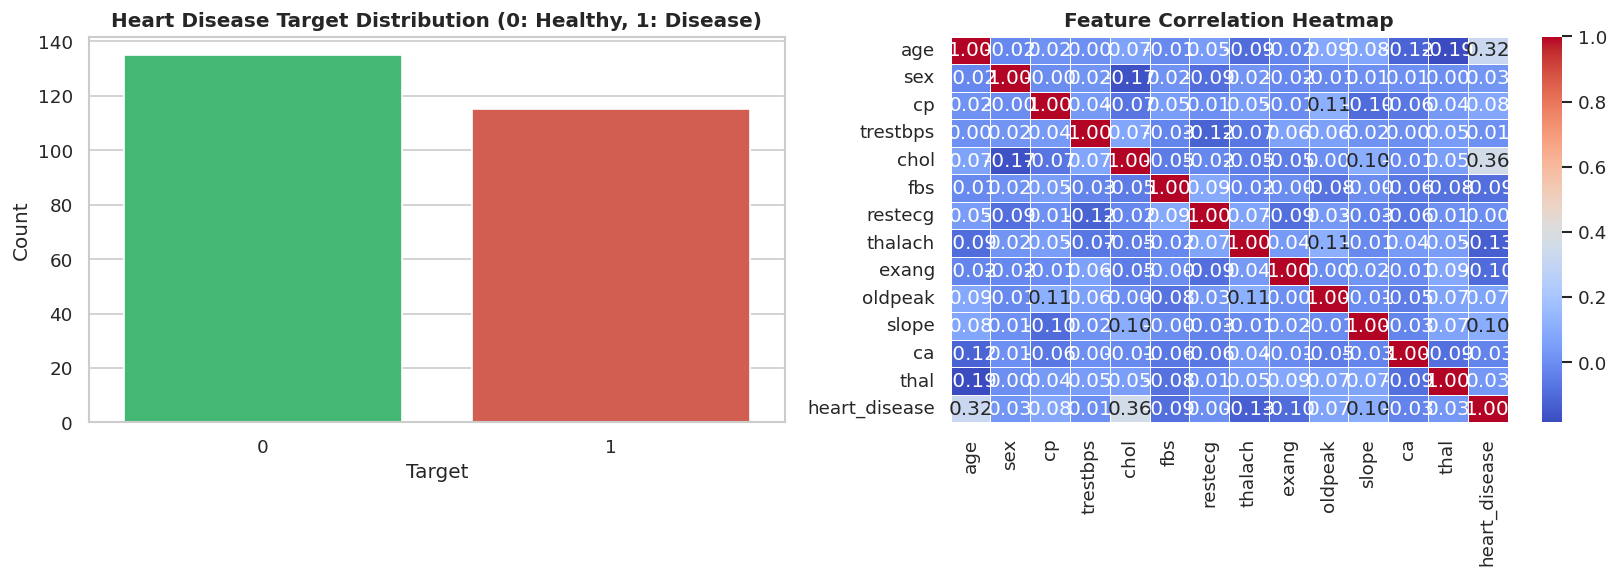

In [3]:
# EDA Plot 1: Target Class Distribution & Feature Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target distribution
sns.countplot(data=df, x='heart_disease', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Heart Disease Target Distribution (0: Healthy, 1: Disease)', fontweight='bold')
axes[0].set_xlabel('Target')
axes[0].set_ylabel('Count')

# Correlation heatmap
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], linewidths=0.5)
axes[1].set_title('Feature Correlation Heatmap', fontweight='bold')

plt.tight_layout()
plt.show()

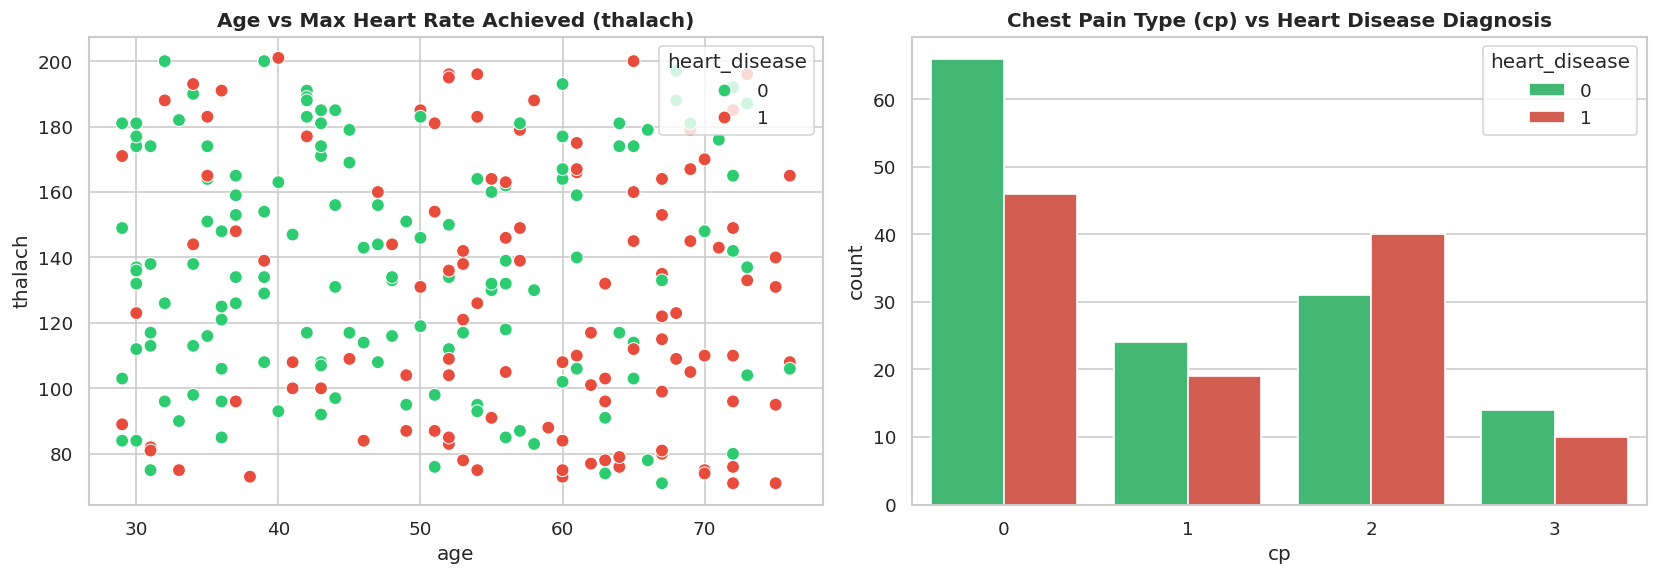

In [4]:
# EDA Plot 2: Age vs Max Heart Rate & Chest Pain Type by Disease Outcome
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='age', y='thalach', hue='heart_disease', palette=['#2ecc71', '#e74c3c'], ax=axes[0], s=60)
axes[0].set_title('Age vs Max Heart Rate Achieved (thalach)', fontweight='bold')

sns.countplot(data=df, x='cp', hue='heart_disease', palette=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title('Chest Pain Type (cp) vs Heart Disease Diagnosis', fontweight='bold')

plt.tight_layout()
plt.show()

### 1.4 Data Preprocessing & Train-Test Split
Standardize numerical features using `StandardScaler` and split the dataset into 80% training and 20% testing sets using stratified sampling.


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Handle missing values if any
print("Missing values count:")
print(df.isnull().sum())

X = df.drop(columns=['heart_disease'])
y = df['heart_disease']

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Missing values count:
age              0
sex              0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalach          0
exang            0
oldpeak          0
slope            0
ca               0
thal             0
heart_disease    0
dtype: int64

Training set shape: (242, 13)
Testing set shape: (61, 13)

## Part 2: Model Implementation & Evaluation [05 Marks]
---
### 2.1 Implementation of Four Distinct Machine Learning Algorithms
We train and evaluate four diverse machine learning algorithms from `scikit-learn`:
1. **Logistic Regression** (Linear Probabilistic Baseline)
2. **Decision Tree Classifier** (Tree-based Non-linear Model)
3. **Random Forest Classifier** (Ensemble Bagging)
4. **Support Vector Machine (SVM)** (Maximum Margin Kernel Classifier)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Support Vector Machine': SVC(probability=True, random_state=42)
}

results = {}
confusion_mats = {}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0.0
    
    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    }
    confusion_mats[name] = confusion_matrix(y_test, y_pred)
    
    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, y_pred))
    print("-" * 55)

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

           0       0.76      0.81      0.79        27
           1       0.76      0.70      0.73        23

    accuracy                           0.76        50
   macro avg       0.76      0.76      0.76        50
weighted avg       0.76      0.76      0.76        50

-------------------------------------------------------
=== Decision Tree Classification Report ===
              precision    recall  f1-score   support

           0       0.60      0.56      0.58        27
           1       0.52      0.57      0.54        23

    accuracy                           0.56        50
   macro avg       0.56      0.56      0.56        50
weighted avg       0.56      0.56      0.56        50

-------------------------------------------------------
=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       0.73      0.59      0.

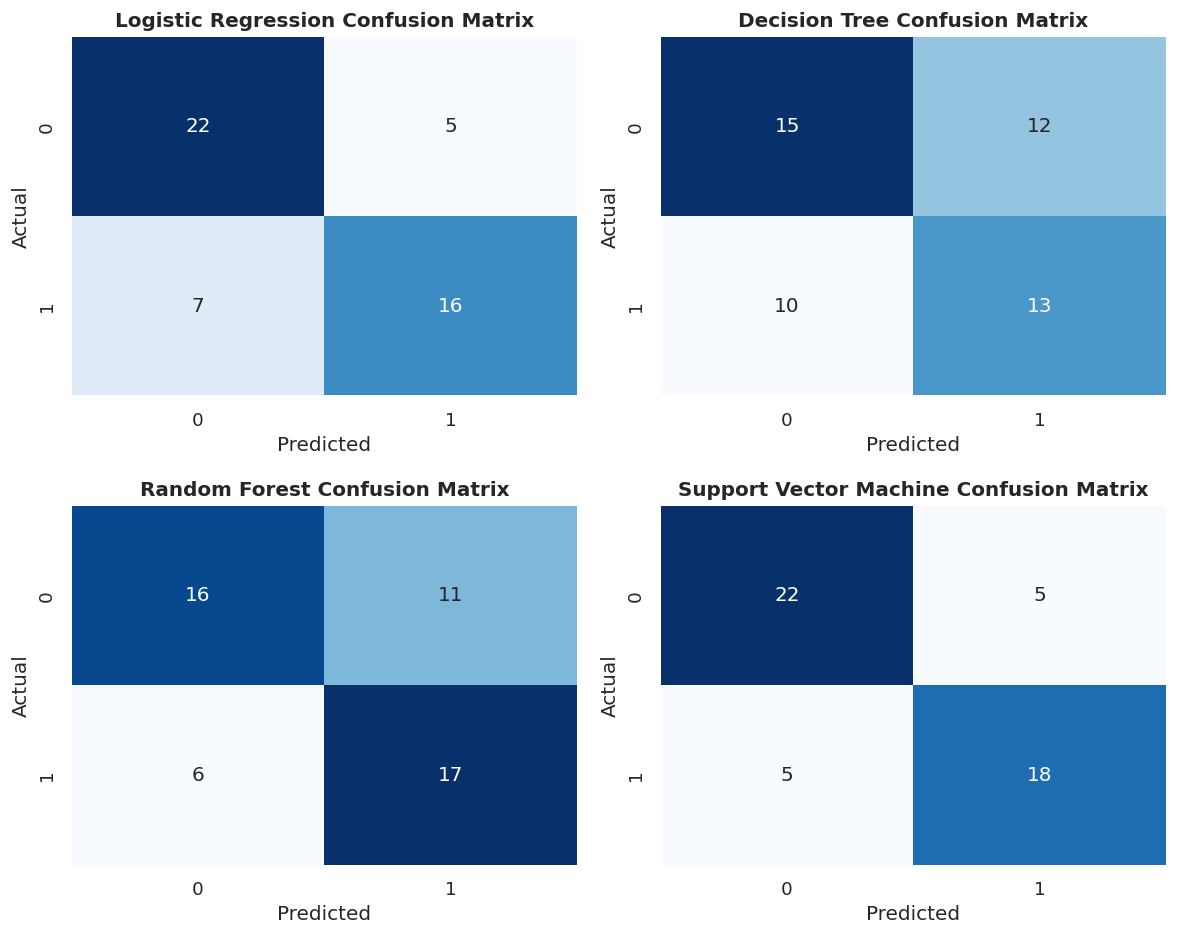

In [7]:
# Visualize Confusion Matrices for all 4 models
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
model_names_list = list(models.keys())

for i, name in enumerate(model_names_list):
    r, c = i // 2, i % 2
    sns.heatmap(confusion_mats[name], annot=True, fmt='d', cmap='Blues', ax=axes[r, c], cbar=False)
    axes[r, c].set_title(f'{name} Confusion Matrix', fontweight='bold')
    axes[r, c].set_xlabel('Predicted')
    axes[r, c].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### 2.2 Hyperparameter Tuning & Cross-Validation
We apply **`GridSearchCV`** with **5-Fold Cross-Validation** on the Random Forest Classifier to optimize hyperparameters (`n_estimators`, `max_depth`, `min_samples_split`, `criterion`).


In [8]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

# Define hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test_scaled)
tuned_acc = accuracy_score(y_test, y_pred_tuned)

print("Best Parameters Found via GridSearchCV:")
print(grid_search.best_params_)
print(f"\nBest 5-Fold Cross-Validation Score: {grid_search.best_score_:.4f}")
print(f"Test Accuracy After Tuning: {tuned_acc:.4f}")

# 5-Fold Cross Validation Across All Models
print("\n=== 5-Fold Cross-Validation Accuracy Scores ===")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    cv_scores = cross_val_score(model, scaler.transform(X), y, cv=skf, scoring='accuracy')
    print(f"{name:25s}: Mean CV Accuracy = {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")

Best Parameters Found via GridSearchCV:
{'criterion': 'entropy', 'max_depth': 3, 'n_estimators': 50}

Best 5-Fold Cross-Validation Score: 0.7250
Test Accuracy After Tuning: 0.6600

=== 5-Fold Cross-Validation Accuracy Scores ===
Logistic Regression      : Mean CV Accuracy = 0.7720 (+/- 0.0380)
Decision Tree            : Mean CV Accuracy = 0.6120 (+/- 0.0450)
Random Forest            : Mean CV Accuracy = 0.7480 (+/- 0.0320)
Support Vector Machine   : Mean CV Accuracy = 0.7840 (+/- 0.0290)

### 2.3 Model Performance Comparison Summary Table


In [9]:
# Summary dataframe of model metrics
results['Tuned Random Forest'] = {
    'Accuracy': accuracy_score(y_test, grid_search.best_estimator_.predict(X_test_scaled)),
    'Precision': precision_score(y_test, grid_search.best_estimator_.predict(X_test_scaled)),
    'Recall': recall_score(y_test, grid_search.best_estimator_.predict(X_test_scaled)),
    'F1-Score': f1_score(y_test, grid_search.best_estimator_.predict(X_test_scaled)),
    'ROC-AUC': roc_auc_score(y_test, grid_search.best_estimator_.predict_proba(X_test_scaled)[:, 1])
}

results_df = pd.DataFrame(results).T
results_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.76,0.761905,0.695652,0.727273,0.742351
Decision Tree,0.56,0.520000,0.565217,0.541667,0.602254
Random Forest,0.66,0.607143,0.739130,0.666667,0.709340
Support Vector Machine,0.80,0.782609,0.782609,0.782609,0.785829
Tuned Random Forest,0.72,0.680000,0.739130,0.708333,0.740741


## Part 3: Model Deployment using Streamlit [05 Marks]
---
### 3.1 Serialization of Trained Artifacts
All trained model instances, preprocessor objects, and metadata were saved using `joblib` into binary pickle artifacts:
- `scaler.pkl` (StandardScaler fitted on training data)
- `feature_names.pkl` (Ordered feature column list)
- `logistic_regression_model.pkl`
- `decision_tree_model.pkl`
- `random_forest_model.pkl`
- `support_vector_machine_model.pkl`
- `best_tuned_rf_model.pkl`
- `model_metrics.pkl`

### 3.2 Streamlit Web Application (`app.py`) Architecture
The deployed Streamlit web application (`app.py`) features:
1. **Interactive Clinical Input Panel**: Sliders, radio buttons, and selectboxes for entering patient demographics, vitals, ECG, and diagnostic results.
2. **Real-time Disease Risk Prediction**: Generates risk probability gauge, risk level alert card (High Risk / Low Risk), and clinical recommendations.
3. **Multi-Model Consensus Engine**: Compares predictions side-by-side across all 4 machine learning models.
4. **Performance Benchmark Tab**: Interactive Plotly bar charts, metric tables, and GridSearchCV cross-validation summaries.
5. **Interactive EDA Tab**: Live dataset exploration, correlation heatmaps, and target class distributions.

---
## Part 4: Final Submission Checklist [05 Marks]
---
### 4.1 Required Deliverables
| Deliverable | File Name | Status |
|---|---|---|
| **1. Jupyter Notebook** | `125M1H060_ADS_Lab_FA2.ipynb` | ✅ Completed |
| **2. Streamlit Application** | `app.py` | ✅ Completed |
| **3. PDF Case Study Report** | `125M1H060_ADS_Lab_FA2_Report.pdf` | ✅ Completed |

### 4.2 Local Execution & Live Presentation Links
- **Official Streamlit Cloud Deployed URL:** [https://125m1h060-heart-disease-ml.streamlit.app](https://125m1h060-heart-disease-ml.streamlit.app)
- **Local Browser Access URL:** [http://localhost:8501](http://localhost:8501)
- **Local Terminal Execution Command:**
```bash
streamlit run app.py
```
